# Swiss rail punctuality and API data quality

**Business question:** How punctual are trains at Switzerland's main stations right now, where and when do delays build up, and how reliable is the real-time data a booking partner would receive from this API?

**Data:** live departure boards from the public Swiss transport API ([transport.opendata.ch](https://transport.opendata.ch)), collected in repeated snapshots.

**Why it matters:** ground transport distribution platforms take carrier data like this and pass it to retailers. Before any analysis, the data has to be checked: missing values, unexpected formats, name changes. This notebook does both: a data quality audit first, then the punctuality analysis.

**Punctuality definition:** a departure counts as on time when it leaves less than 3 minutes late, the threshold SBB uses for its own punctuality figures.

## 1. Setup

In [16]:
import time
from datetime import datetime

import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

BASE_URL = "https://transport.opendata.ch/v1"

STATIONS = ["Zürich HB", "Bern", "Basel SBB", "Genève", "Lausanne",
            "Luzern", "Winterthur", "St. Gallen"]

DEPARTURES_PER_STATION = 150   # departures requested per station per snapshot
SNAPSHOTS = 12                  # how many times to collect (8 x 15 min = 2 hours)
MINUTES_BETWEEN = 15           # wait between snapshots
ON_TIME_THRESHOLD = 3          # minutes, SBB definition

## 2. Calling the API

`get_json` sends a GET request, checks the status code and retries on server errors (5xx) or timeouts. A 4xx error means the request itself is wrong, so it is not retried. This is the same logic you would document for a partner integration.

In [17]:
def get_json(endpoint, params, retries=3, wait=5):
    url = f"{BASE_URL}/{endpoint}"
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, params=params, timeout=20)
        except requests.exceptions.RequestException as e:
            print(f"  attempt {attempt}: connection problem ({e.__class__.__name__})")
            time.sleep(wait)
            continue
        if r.status_code == 200:
            return r.json()
        if 400 <= r.status_code < 500:
            print(f"  {r.status_code} client error for {params}: not retrying")
            return None
        print(f"  attempt {attempt}: {r.status_code} server error, retrying in {wait}s")
        time.sleep(wait)
    return None


# Quick test: one station, three departures
test = get_json("stationboard", {"station": "Bern", "limit": 3})
test["stationboard"][0] if test else "No response"

{'stop': {'station': {'id': '8507000',
   'name': 'Bern',
   'score': None,
   'coordinate': {'type': 'WGS84', 'x': 46.948831, 'y': 7.439129},
   'distance': None},
  'arrival': None,
  'arrivalTimestamp': None,
  'departure': '2026-10-26T07:01:00+0100',
  'departureTimestamp': 1792994460,
  'delay': 0,
  'platform': '22',
  'prognosis': {'platform': None,
   'arrival': '2026-10-26T07:01:34+0100',
   'departure': '2026-10-26T07:01:00+0100',
   'capacity1st': None,
   'capacity2nd': None},
  'realtimeAvailability': None,
  'location': {'id': '8508055',
   'name': None,
   'score': None,
   'coordinate': {'type': 'WGS84', 'x': None, 'y': None},
   'distance': None}},
 'name': '009071',
 'category': 'S',
 'subcategory': None,
 'categoryCode': None,
 'number': '9',
 'operator': 'RBS',
 'to': 'Unterzollikofen',
 'passList': [{'station': {'id': '8508055',
    'name': None,
    'score': None,
    'coordinate': {'type': 'WGS84', 'x': None, 'y': None},
    'distance': None},
   'arrival': None,

## 3. Turning nested JSON into a table

Each departure is a nested object. `flatten_departure` pulls out the fields we need: line, train type, operator, destination, planned and forecast time, delay and platform.

In [18]:
def flatten_departure(dep, station_queried, snapshot_time):
    stop = dep.get("stop") or {}
    prog = stop.get("prognosis") or {}
    return {
        "snapshot_time": snapshot_time,
        "station_queried": station_queried,
        "station_returned": (stop.get("station") or {}).get("name"),
        "category": dep.get("category"),
        "number": dep.get("number"),
        "line": f"{dep.get('category') or ''} {dep.get('number') or ''}".strip(),
        "operator": dep.get("operator"),
        "destination": dep.get("to"),
        "planned_departure": stop.get("departure"),
        "forecast_departure": prog.get("departure"),
        "delay_min": stop.get("delay"),
        "planned_platform": stop.get("platform"),
        "forecast_platform": prog.get("platform"),
    }


def collect_snapshot():
    snapshot_time = datetime.now().isoformat(timespec="seconds")
    rows = []
    for station in STATIONS:
        data = get_json("stationboard", {"station": station, "limit": DEPARTURES_PER_STATION})
        if not data:
            print(f"  no data for {station}")
            continue
        board = data.get("stationboard") or []
        rows += [flatten_departure(d, station, snapshot_time) for d in board]
        time.sleep(1)  # be polite to a free public API
    return rows

## 4. Collecting snapshots

Delays are only known close to departure, so one call gives a limited picture. This cell collects a snapshot every 15 minutes and saves to CSV after each one, so nothing is lost if you stop early. With the default settings it runs for about 2 hours. Set `SNAPSHOTS = 1` in the setup cell for a quick test.

In [19]:
all_rows = []
for i in range(SNAPSHOTS):
    print(f"Snapshot {i + 1} of {SNAPSHOTS} at {datetime.now():%H:%M}")
    all_rows += collect_snapshot()
    pd.DataFrame(all_rows).to_csv("raw_departures.csv", index=False)
    print(f"  rows so far: {len(all_rows)}")
    if i < SNAPSHOTS - 1:
        time.sleep(MINUTES_BETWEEN * 60)

raw = pd.DataFrame(all_rows)
raw.shape

Snapshot 1 of 12 at 07:01
  rows so far: 1201
Snapshot 2 of 12 at 07:16
  rows so far: 2403
Snapshot 3 of 12 at 07:44
  rows so far: 3607
Snapshot 4 of 12 at 07:59
  rows so far: 4809
Snapshot 5 of 12 at 08:15
  rows so far: 6010
Snapshot 6 of 12 at 08:30
  rows so far: 7213
Snapshot 7 of 12 at 08:45
  rows so far: 8413
Snapshot 8 of 12 at 09:00
  rows so far: 9614
Snapshot 9 of 12 at 09:15
  rows so far: 10817
Snapshot 10 of 12 at 09:31
  rows so far: 12019
Snapshot 11 of 12 at 09:46
  rows so far: 13220
Snapshot 12 of 12 at 10:01
  rows so far: 14420


(14420, 13)

If you already have `raw_departures.csv` from an earlier run, you can skip the collection cell and load it here instead.

In [20]:
# raw = pd.read_csv("raw_departures.csv")
raw.head()

,snapshot_time,station_queried,station_returned,category,number,line,operator,destination,planned_departure,forecast_departure,delay_min,planned_platform,forecast_platform
0,2026-10-26T07:01:35,Zürich HB,Zürich HB,S,6,S 6,SBB,Baden,2026-10-26T07:01:00+0100,2026-10-26T07:01:00+0100,0.0,41/42,None
1,2026-10-26T07:01:35,Zürich HB,Zürich HB,S,11,S 11,SBB,Seuzach,2026-10-26T07:01:00+0100,2026-10-26T07:02:00+0100,1.0,43/44,None
2,2026-10-26T07:01:35,Zürich HB,Zürich HB,IC,5,IC 5,SBB,Rorschach,2026-10-26T07:02:00+0100,2026-10-26T07:02:00+0100,0.0,33,None
3,2026-10-26T07:01:35,Zürich HB,Zürich HB,IC,8,IC 8,SBB,Brig,2026-10-26T07:02:00+0100,2026-10-26T07:02:00+0100,0.0,31,None
4,2026-10-26T07:01:35,Zürich HB,Zürich HB,S,3,S 3,SBB,Wetzikon ZH,2026-10-26T07:04:00+0100,2026-10-26T07:04:00+0100,0.0,43/44,None


## 5. Data quality audit

Before any analysis: what is missing, what is in an unexpected format, and what would surprise a partner using this data?

In [21]:
audit = pd.DataFrame({
    "missing_values": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(1),
})
audit

,missing_values,missing_pct
snapshot_time,0,0.0
station_queried,0,0.0
station_returned,0,0.0
category,0,0.0
number,0,0.0
line,0,0.0
operator,0,0.0
destination,0,0.0
planned_departure,0,0.0
forecast_departure,6279,43.5


In [22]:
df = raw.copy()
df["planned_departure"] = pd.to_datetime(df["planned_departure"], utc=True, errors="coerce")
df["forecast_departure"] = pd.to_datetime(df["forecast_departure"], utc=True, errors="coerce")
df["delay_min"] = pd.to_numeric(df["delay_min"], errors="coerce")

key = ["station_queried", "line", "destination", "planned_departure"]
uniq = df.sort_values("snapshot_time").drop_duplicates(subset=key, keep="last")
platform_change = uniq["forecast_platform"].notna() & (uniq["forecast_platform"] != uniq["planned_platform"])

checks = {
    "Rows collected (all snapshots)": len(df),
    "Unique departures": len(uniq),
    "Unique departures with a real-time delay value": int(uniq["delay_min"].notna().sum()),
    "Unique departures with a platform change": int(platform_change.sum()),
    "Station name returned differently from the query": int((uniq["station_returned"] != uniq["station_queried"]).sum()),
    "Unparseable planned times": int(uniq["planned_departure"].isna().sum()),
}
quality_pct = {
    "Have real-time delay data": round(uniq["delay_min"].notna().mean() * 100, 1),
        "Forecast platform field filled": round(uniq["forecast_platform"].notna().mean() * 100, 1),
    "Station name differs from query": round((uniq["station_returned"] != uniq["station_queried"]).mean() * 100, 1),
    "Planned time missing or unreadable": round(uniq["planned_departure"].isna().mean() * 100, 1),
}
pd.Series(checks, name="value").to_frame()

,value
Rows collected (all snapshots),14420
Unique departures,2164
Unique departures with a real-time delay value,1584
Unique departures with a platform change,0
Station name returned differently from the query,0
Unparseable planned times,0


In [23]:
# Name normalisation and coordinate check, using the locations endpoint
loc = get_json("locations", {"query": "Geneva", "type": "station"})
first = loc["stations"][0] if loc and loc.get("stations") else {}
print("Query 'Geneva' returns:", first.get("name"))
print("Coordinates:", first.get("coordinate"))
print("Note: in this API, x holds the latitude (~46) and y the longitude (~6). "
      "Most systems expect the opposite, so a partner plotting stations would need to swap them.")

Query 'Geneva' returns: Genève
Coordinates: {'type': 'WGS84', 'x': 46.210212, 'y': 6.142455}
Note: in this API, x holds the latitude (~46) and y the longitude (~6). Most systems expect the opposite, so a partner plotting stations would need to swap them.


## 6. Cleaning

The same train appears in several snapshots. Keep only the latest snapshot for each departure, because its delay value is the most recent. Then keep departures with a real-time delay value.

In [24]:
latest = uniq.copy()

# Keep only departures that were close to leaving when the snapshot was taken.
# Further-ahead departures often show a delay of 0 simply because nothing has happened yet,
# which would make punctuality look better than it is.
snap = pd.to_datetime(latest["snapshot_time"]).dt.tz_localize("Europe/Zurich").dt.tz_convert("UTC")
minutes_ahead = (latest["planned_departure"] - snap).dt.total_seconds() / 60
latest = latest[minutes_ahead <= MINUTES_BETWEEN]

clean = latest.dropna(subset=["delay_min", "planned_departure"]).copy()

clean["on_time"] = clean["delay_min"] < ON_TIME_THRESHOLD
clean["hour"] = clean["planned_departure"].dt.tz_convert("Europe/Zurich").dt.hour
clean["category"] = clean["category"].fillna("unknown")

print(f"{len(df)} rows -> {len(uniq)} unique departures -> {len(latest)} close to departure -> {len(clean)} with delay data")
clean.to_csv("clean_departures.csv", index=False)

14420 rows -> 2164 unique departures -> 991 close to departure -> 946 with delay data


## 7. Punctuality analysis

In [25]:
overall = clean["on_time"].mean() * 100
print(f"Unique departures analysed: {len(clean)}")
print(f"On time (< {ON_TIME_THRESHOLD} min late): {overall:.1f}%")
print(f"Average delay: {clean['delay_min'].mean():.2f} min")
print(f"Departures 5+ min late: {(clean['delay_min'] >= 5).mean() * 100:.1f}%")
print(f"Largest delay: {clean['delay_min'].max():.0f} min")

Unique departures analysed: 946
On time (< 3 min late): 98.1%
Average delay: 0.29 min
Departures 5+ min late: 0.6%
Largest delay: 13 min


In [26]:
by_station = (clean.groupby("station_queried")
              .agg(departures=("on_time", "size"),
                   on_time_pct=("on_time", lambda s: round(s.mean() * 100, 1)),
                   avg_delay_min=("delay_min", lambda s: round(s.mean(), 2)))
              .sort_values("on_time_pct"))
by_station

,departures,on_time_pct,avg_delay_min
station_queried,,,
Lausanne,89,91.0,0.56
St. Gallen,79,96.2,0.43
Genève,78,97.4,0.36
Bern,180,98.9,0.17
Zürich HB,263,98.9,0.35
Basel SBB,62,100.0,0.03
Luzern,79,100.0,0.35
Winterthur,116,100.0,0.10


In [27]:
by_category = (clean.groupby("category")
               .agg(departures=("on_time", "size"),
                    on_time_pct=("on_time", lambda s: round(s.mean() * 100, 1)),
                    avg_delay_min=("delay_min", lambda s: round(s.mean(), 2)))
               .query("departures >= 10")
               .sort_values("on_time_pct"))
by_category

,departures,on_time_pct,avg_delay_min
category,,,
EC,10,90.0,0.90
TER,10,90.0,1.60
R,69,95.7,0.29
RE,63,96.8,0.24
IR,168,97.0,0.32
S,499,99.0,0.28
IC,112,99.1,0.15


In [28]:
by_hour = (clean.groupby("hour")
           .agg(departures=("on_time", "size"),
                on_time_pct=("on_time", lambda s: round(s.mean() * 100, 1)),
                avg_delay_min=("delay_min", lambda s: round(s.mean(), 2))))
by_hour

,departures,on_time_pct,avg_delay_min
hour,,,
7,239,98.3,0.28
8,307,98.4,0.28
9,295,96.9,0.35
10,105,100.0,0.18


## 8. Charts

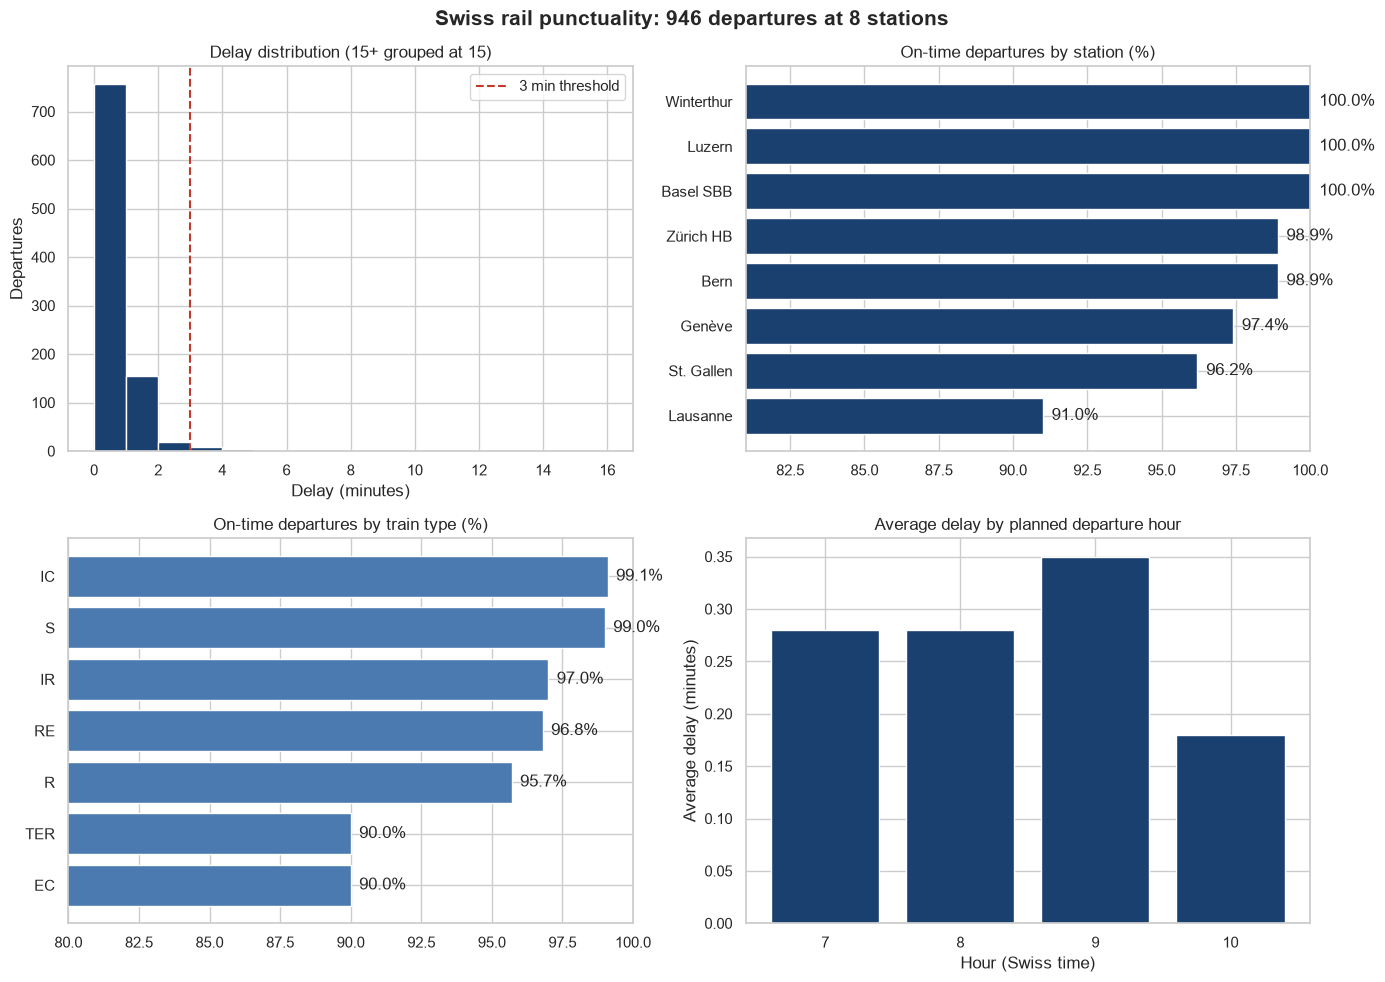

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Delay distribution
clip = clean["delay_min"].clip(upper=15)
axes[0, 0].hist(clip, bins=range(0, 17), color="#1a4070", edgecolor="white")
axes[0, 0].axvline(ON_TIME_THRESHOLD, color="#c0392b", linestyle="--", label="3 min threshold")
axes[0, 0].set_title("Delay distribution (15+ grouped at 15)")
axes[0, 0].set_xlabel("Delay (minutes)")
axes[0, 0].set_ylabel("Departures")
axes[0, 0].legend()

# 2. On-time rate by station
s = by_station.sort_values("on_time_pct")
axes[0, 1].barh(s.index, s["on_time_pct"], color="#1a4070")
axes[0, 1].set_title("On-time departures by station (%)")
axes[0, 1].set_xlim(max(0, s["on_time_pct"].min() - 10), 100)
for i, v in enumerate(s["on_time_pct"]):
    axes[0, 1].text(v + 0.3, i, f"{v}%", va="center")

# 3. On-time rate by train type
c = by_category.sort_values("on_time_pct")
axes[1, 0].barh(c.index, c["on_time_pct"], color="#4a7ab0")
axes[1, 0].set_title("On-time departures by train type (%)")
axes[1, 0].set_xlim(max(0, c["on_time_pct"].min() - 10), 100)
for i, v in enumerate(c["on_time_pct"]):
    axes[1, 0].text(v + 0.3, i, f"{v}%", va="center")

# 4. Average delay by hour
axes[1, 1].bar(by_hour.index.astype(str), by_hour["avg_delay_min"], color="#1a4070")
axes[1, 1].set_title("Average delay by planned departure hour")
axes[1, 1].set_xlabel("Hour (Swiss time)")
axes[1, 1].set_ylabel("Average delay (minutes)")

plt.suptitle(f"Swiss rail punctuality: {len(clean)} departures at {clean['station_queried'].nunique()} stations",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("punctuality_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

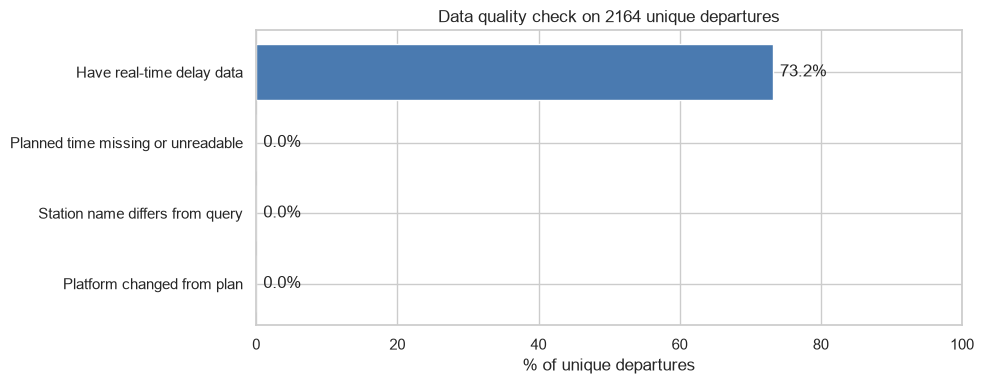

In [30]:
fig, ax = plt.subplots(figsize=(10, 4))
q = pd.Series(quality_pct).sort_values()
ax.barh(q.index, q.values, color="#4a7ab0")
ax.set_xlim(0, 100)
ax.set_xlabel("% of unique departures")
ax.set_title(f"Data quality check on {len(uniq)} unique departures")
for i, v in enumerate(q.values):
    ax.text(v + 1, i, f"{v}%", va="center")
plt.tight_layout()
plt.savefig("data_quality_findings.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Findings

Write these from your own results once the run has finished. Keep each one to a number and what it means.

1. **Overall punctuality:** X% of N departures left less than 3 minutes late; average delay Y minutes.
2. **Where delays build up:** station with the lowest on-time rate, and by how much.
3. **Which trains:** train type with the lowest on-time rate (long-distance vs regional vs S-Bahn).
4. **When:** hour with the highest average delay.
5. **Data quality for partners:** share of departures with real-time data, number of platform changes, name normalisation (Geneva returns Genève), and the latitude/longitude order in the coordinate fields.

**What I would tell a booking partner integrating this data:** match stations by ID rather than name, treat a missing delay as "no real-time data" rather than "on time", show forecast platforms when they differ from planned ones, and swap x and y before plotting coordinates.